For immersion: https://www.youtube.com/watch?v=sdBrscwwy_c

# 🌟 Operation NeuroNexus

Trondheim lies under the iron grip of SkyNet, an AI system that has seized control of the city's entire digital infrastructure. You and your team of elite hackers have been tasked with a crucial mission: infiltrate SkyNet's systems, decode its defenses, and liberate the city from its digital oppressor.

## 🎯 Mission Overview

Operation NeuroNexus consists of four independent, yet interconnected missions. Each mission targets a different aspect of SkyNet's infrastructure and requires you to apply various Supervised Learning techniques covered in this course.

## 📊 Mission Structure

1. Each mission has a specific task related to combating SkyNet.
2. Following the task description, you'll find a set of formal requirements that your solution must meet.
3. The primary measure of your success is the accuracy of your machine learning model.
4. After completing each task, you must answer a series of questions to demonstrate your understanding of the techniques used.

## 🧪 A Note on Test Data

In a departure from real-world scenarios, you will have access to the target variables of the test sets for each mission. This has been arranged to facilitate the evaluation of your models. However, remember that in actual machine learning projects, test targets are not available, as predicting these is the ultimate goal of your supervised models.

## 📝 Submission Guidelines

- For each mission, provide your code solution and model results inside this notebook.
- Answer the follow-up questions in markdown format within this notebook. A few sentences is enough, no requirements for length of answers.
- Ensure your explanations are clear, concise, and demonstrate a deep understanding of the techniques employed.


Good luck! The resistance is counting on you.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 🌞 Mission 1: Predicting SkyNet's Power Consumption

### 🎯 The Mission
Intelligence suggests that SkyNet has a critical weakness: **its power consumption**. We must understand its energy needs to plan a coordinated strike.

### 🧠 Your Task
Develop a predictive model to estimate SkyNet's power consumption based on its **Network Activity**.

**Goal**: Implement a **Linear Regression model using Gradient Descent, from scratch**.

Use `LinearRegression` class from `linear_regression.py` stored in this folder. Your task is to complete two functions: `fit` (find the optimal parameters of the regression) and `predict` (apply them to the test data).

> Note: The `%autoreload` IPython magic command allows instant updates from `linear_regression.py`.

### 📊 Formal Requirements
1. **Implementation**: 
   - Use standard Python libraries (numpy, math, pandas, etc.)
   - Implement gradient descent

2. **Discussion**:

   a. Visualize the fitted curve. Derive the resulting Energy consumption formula.
   
   b. Analyze prediction error distribution. What is an unbiased estimator?

---

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# Import your implementation
from linear_regression import LinearRegression # <--- This is your implementation~

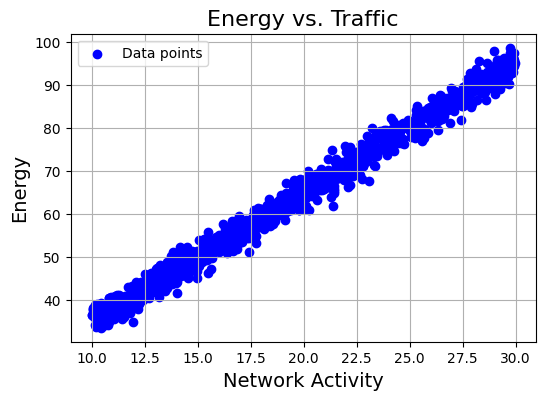

In [4]:
# Load data
data = pd.read_csv('mission1.csv')

plt.figure(figsize=(6, 4))
plt.scatter(data['Net_Activity'], data['Energy'], c='blue', label='Data points')
plt.grid(True)
plt.xlabel('Network Activity', fontsize=14)
plt.ylabel('Energy', fontsize=14)
plt.title('Energy vs. Traffic', fontsize=16)
plt.legend()
plt.show()

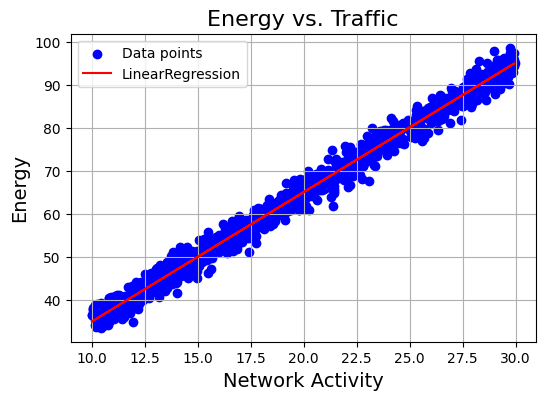

In [5]:
X = data['Net_Activity']
y = data['Energy']

# The reason for the low learning rate and large number of epochs is due to the fact that the loss function
# blows up in the first couple of epochs due to the initialized weights (0) being very far off from the final weights.
# Can be fixed through scaling the data down or initializing the weights at a higher value. 
lr = LinearRegression(learning_rate=0.002,epochs=10000)
lr.fit(X,y)

plt.figure(figsize=(6, 4))
plt.scatter(X, y, c='blue', label='Data points')
plt.grid(True)
plt.plot(X,lr.predict(X),c='red',label='LinearRegression')
plt.xlabel('Network Activity', fontsize=14)
plt.ylabel('Energy', fontsize=14)
plt.title('Energy vs. Traffic', fontsize=16)
plt.legend()
plt.show()

#### Discussion: Energy consumption formula and error
We can derive the formula from the model from its weights (and bias term). In a linear regressor, the prediction formula is $\hat{y} = \mathbf{w} \cdot \mathbf{x} + b$. We can compare the model prediction with the MLE for linear regression.

In [6]:
xmean = np.mean(data['Net_Activity'])
ymean = np.mean(data['Energy'])
m = sum([(xi-xmean)*(yi-ymean) for xi,yi in zip(data['Net_Activity'],data["Energy"])])/sum([(xi-xmean)**2 for xi in data["Net_Activity"]])
c = ymean - m*xmean

print(f"Formula for energy (y) given network activity (x) found by the model:\
      \ny = {lr.weights}*x + {lr.bias}\n")
print(f"Formula for energy (y) given network activity (x) via MLE:\
      \ny = {m}*x + {c}")

Formula for energy (y) given network activity (x) found by the model:      
y = 3.019371441729837*x + 4.660461314699462

Formula for energy (y) given network activity (x) via MLE:      
y = 3.0086965538001316*x + 4.891704780872644


An unbiased estimator is an estimator whose expected value is the parameter it estimates. Another way of putting it is that or that the expected error is centered around 0, or $E[error] = E[\hat{\theta}] - E[\theta] = 0$. Here our estimator is the linear model and we are trying to estimate the energy consumption. From the graph below we see that the error is approximately normally distributed around 0, meaning our model is practically unbiased.

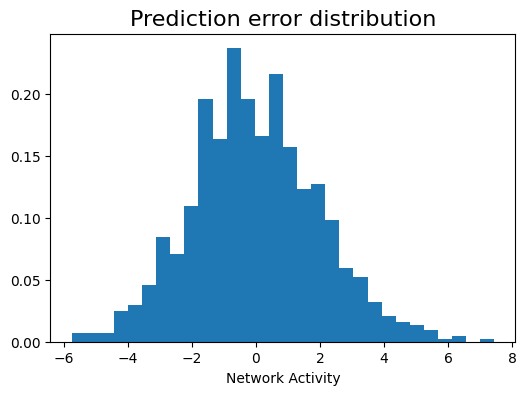

Average (expected) error: -0.0175


In [7]:
plt.figure(figsize=(6, 4))
plt.hist(x=lr.predict(X)-data['Energy'],bins=30,density=True)
plt.xlabel('Network Activity', fontsize=10)
plt.title('Prediction error distribution', fontsize=16)
plt.show()
print(f"Average (expected) error: {np.mean(lr.predict(X)-data['Energy']):.4f}")

## 🧠 Mission 2: Decoding SkyNet's signals

### 🌐 The Discovery
We've intercepted two types of signals that may determine SkyNet's next moves.

### 🎯 Your Mission
1. Evolve your linear regression into logistic regression
2. Engineer features to unravel hidden connections
3. Predict SkyNet's binary decisions (0 or 1) from paired signals

### 📊 Formal Requirements
1. **Implementation**: 
   - Use standard Python libraries
   - Implement gradient descent

2. **Performance**: Achieve at least 0.88 accuracy on the test set

3. **Discussion**:

   a. Explain poor initial performance and your improvements

   b. What is the model's inductive bias. Why is it important?

   c. Try to solve the problem using `sklearn.tree.DecisionTreeClassifier`. Can it solve the problem? Why/Why not?
   
   d. Plot the ROC curve

---

In [8]:
data = pd.read_csv('mission2.csv')
train = data[data['split'] == 'train']
test = data[data['split'] == 'test']
train = train.drop("split",axis=1)
test = test.drop("split",axis=1)

##### EDA / Feature engineering

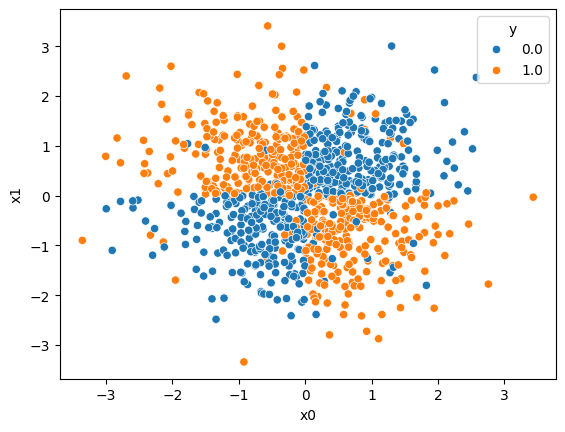

In [9]:
ax = sns.scatterplot(x='x0',y='x1',hue='y',data=data)

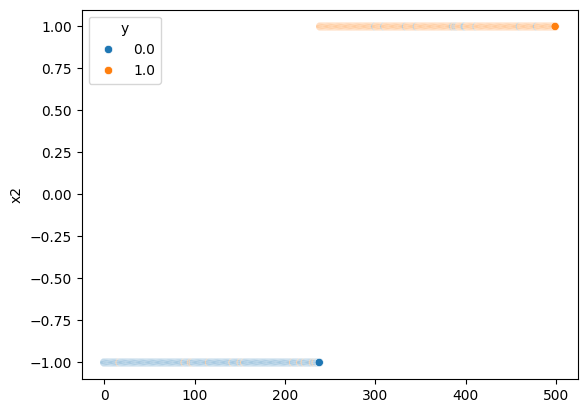

In [10]:
def feature_engineering(df):
    df['x2'] = -np.sign(df['x0'] * df['x1']) 
    return df

train = feature_engineering(train)
test = feature_engineering(test)
train = train.sort_values(by='x2')
ax = sns.scatterplot(x=range(len(train)),y='x2',hue='y',data=train)
plt.show()

##### Training

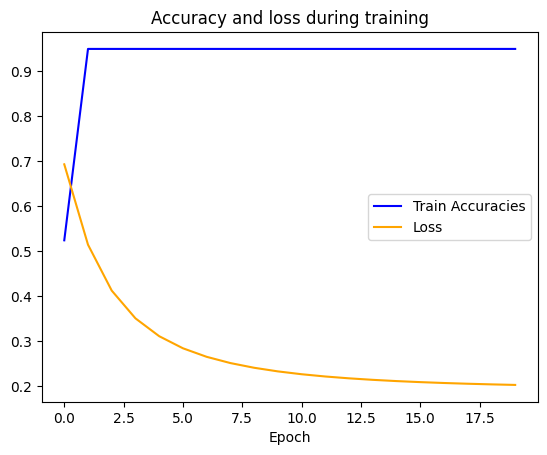

In [11]:
from logistical_regression import LogisticRegression
epochs = 20
lr = LogisticRegression(epochs=epochs,learning_rate=1)

x_train = train[['x0','x1','x2']]
y_train = train['y']
x_test = test[['x0','x1','x2']]
y_test = test['y']

lr.fit(x_train,y_train)

plt.plot(lr.train_accuracies, color="blue", label="Train Accuracies")
plt.plot(lr.losses, color="orange", label="Loss")
plt.title("Accuracy and loss during training")
plt.xlabel("Epoch")
plt.legend()
plt.show()

In [12]:
# Testing with test set
pred_acc = np.mean(lr.predict(x_test) == y_test)
print("Accuracy =",pred_acc)

Accuracy = 0.95


##### Discussion

a) Logistical regression performs well on features with linear relationships. The poor intial performance (i.e. using un-engineered data) is due to the fact that there is no linear relationship between x0, x1, and y.

b) What is the model's inductive bias. Why is it important?
Inductive bias is the set of assumptions a model makes to generalize from limited data. For linear/logistic regression for example, we assume a linear relationship between the features. It is important to mind the model's inductive bias because whenever we choose a certain model, we are implicitly assuming that the data follows some particular distribution. In this exercise, applying a logistic regression on the raw data does not work well because it assumes linear relationships where none exists. 

##### Solving with DTC

The DTC works well in this instance because the class can be accurately predicted by splitting criteria along x0 and x1. We can imagine for example that the tree has learned to split on x0 > 0 and x1 > 0, giving 4 possible combinations of features, which (as we can see from the scatterplot) gives a very good indication of the class.

In [13]:
# Solving with decision tree
x_train_tree = train[['x0','x1']]
y_train_tree = train['y']
x_test_tree = test[['x0','x1']]
y_test_tree = test['y']

from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=3) # smaller depth gives better results
clf.fit(x_train_tree,y_train_tree)

,criterion,'gini'
,splitter,'best'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


##### ROC Curves

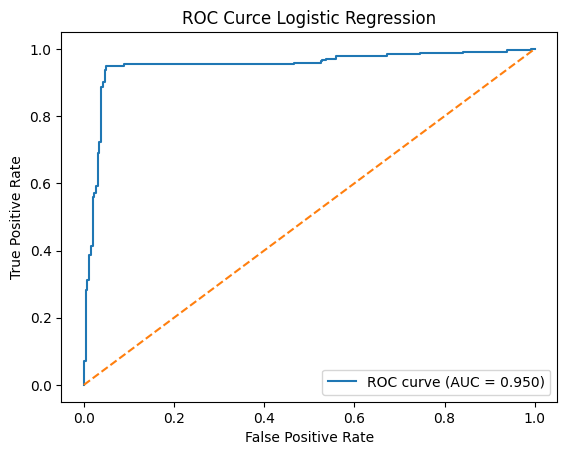

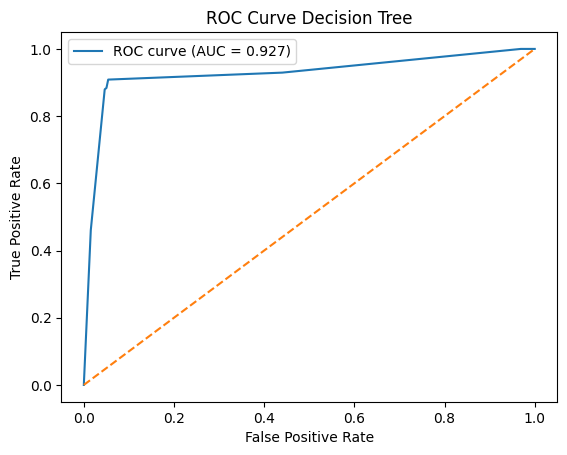

In [14]:
# Plotting ROC for the logistic regression
from sklearn.metrics import roc_curve, roc_auc_score

lin_model = np.dot(x_test,lr.weights) + lr.bias
y_probs = lr.sigmoid_function(lin_model)
fpr, tpr, thresholds = roc_curve(y_test,y_probs)
auc_score = roc_auc_score(y_test,y_probs)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curce Logistic Regression')
plt.legend()
plt.show()

# Plotting ROC for decision tree

y_probs = clf.predict_proba(x_test_tree)[:,1]
fpr, tpr, thresholds = roc_curve(y_test_tree,y_probs)
auc_score = roc_auc_score(y_test_tree,y_probs)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Decision Tree')
plt.legend()
plt.show()



## 🌆 Mission 3: CyberGuard

### 🌐 The Discovery
SkyNet's drone communications use binary encryption. We need a system to intercept these messages.

### 🎯 Your Mission
Develop a decision tree classifier to process intercepted communications. Use `sklearn.tree.DecisionTreeClassifier`. 

Only one of the data streams needs to be decrypted, but you will need to identify the correct one.

To decrypt a data stream, transform the data into a binary representation based on whether the feature is even or odd.

### 📊 Formal Requirements
1. **Accuracy**: Achieve ROC AUC >= 0.72 on the test set
2. **Discussion**:

   a. Explain your threshold-breaking strategy. Did you change the default hyperparameters?

   b. Justify ROC AUC usage. Plot and interpret ROC.
   
   c. Try to solve the problem using sklearn’s Random Forest Classifier. Compare the results.

---

In [15]:
train = pd.read_csv('mission3_train.csv')
test = pd.read_csv('mission3_test.csv')

In [16]:
def feature_engineering(df: pd.DataFrame, stream):
    # transform based on power of 10
    df[f'data_stream_{stream}'] = ((df[f'data_stream_{stream}'] * 10**3) % 2).astype(int)
    df = df.drop('target',axis=1)
    return df

In [17]:
from sklearn.tree import DecisionTreeClassifier

# I arrived on the conclusion that stream 3 is the encrypted stream from trial and error. 
# Decrypting this stream is the one that gives the best result.
x_train = feature_engineering(train.copy(),3)
y_train = train['target'].copy()
x_test = feature_engineering(test.copy(),3)
y_test = test['target'].copy()

clf = DecisionTreeClassifier(max_depth=6)
clf.fit(x_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,6
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


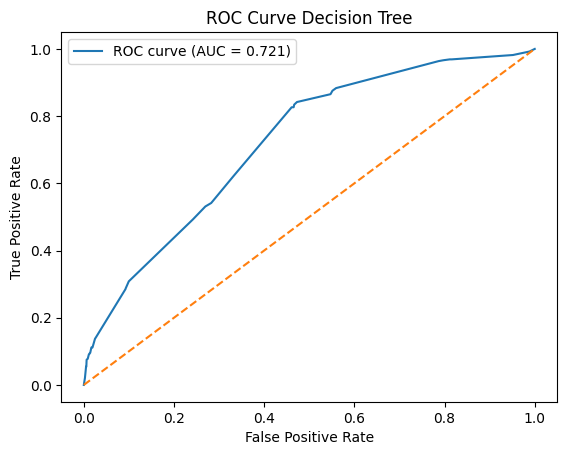

In [18]:
from sklearn.metrics import roc_curve, roc_auc_score
y_probs = clf.predict_proba(x_test)[:,1]
auc_score = roc_auc_score(y_test,y_probs)
fpr, tpr, thresholds = roc_curve(y_test,y_probs)

plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Decision Tree')
plt.legend()
plt.show() 

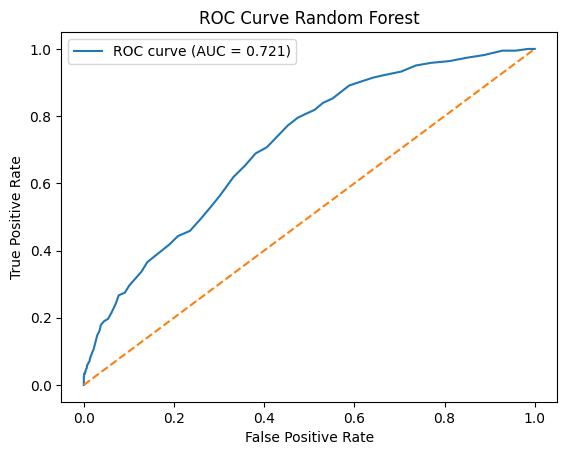

In [19]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier()
clf.fit(x_train,y_train)

y_probs = clf.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test,y_probs)
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Random Forest')
plt.legend()
plt.show() 

##### Discussion

a) The thresholds are explored in the ROC curve. We can choose the threshold depending on our preference for high TPR or low FPR, or for example by choosing the threshold that gives the biggest distance between the ROC curve from the TPR = FPR line, meaning the threshold that is farthest from a random guess. I changed the default hyperparameters in the DTC by hand until I found one that worked best. Because we only have 11 features here, we can expect that after max_depth = 20 or so we dont get very different results, meaning the "parameter search space" is small and searching by hand was fine.

b) Intuitively, we would like to choose a model that gives an estimate farthest possible from a random guess, regardless of threshold. This translates to choosing a model whose ROC curve is "farthest possible" from the TPR = FPR at every threshold, so the AUC is a natural measure. From this DTC ROC curve we see that a threshold that gives a high TPR (about 0.8) and middle FPR (about 0.5) is the one that gives the least random estimate.

c) The results are nearly identical with a DTC or a RFC. A disadvantage is that the RFC took significantly longer to train. An advantage is that we did not have to perform any hyperparameter tuning.

## ⚡ Final Mission: Mapping SkyNet's Energy Nexus

### 🌐 The Discovery
SkyNet is harvesting energy from Trondheim's buildings. Some structures provide significantly more power than others.

### 🎯 Your Mission
Predict the **Nexus Rating** of unknown buildings in Trondheim (test set).

### 🧠 The Challenge
1. **Target**: Transform the Nexus Rating to reveal true energy hierarchy
2. **Data Quality**: Handle missing values and categorical features
3. **Ensembling**: Use advanced models and ensemble learning

### 💡 Hint
You suspect that an insider has tampered with the columns in the testing data... 

Compare the training and test distributions and try to rectify the test dataset.

### 📊 Formal Requirements
1. **Performance**: Achieve RMSLE <= 0.294 on the test set
2. **Discussion**:

   a. Explain your threshold-breaking strategy

   b. Justify RMSLE usage. Why do we use this metric? Which loss function did you use?

   c. Plot and interpret feature importances

   d. Describe your ensembling techniques

   e. In real life, you do not have the test targets. How would you make sure your model will work good on the unseen data? 

---

In [20]:
train = pd.read_csv('final_mission_train.csv')
test = pd.read_csv('final_mission_test.csv')

Text(0, 0.5, 'Count')

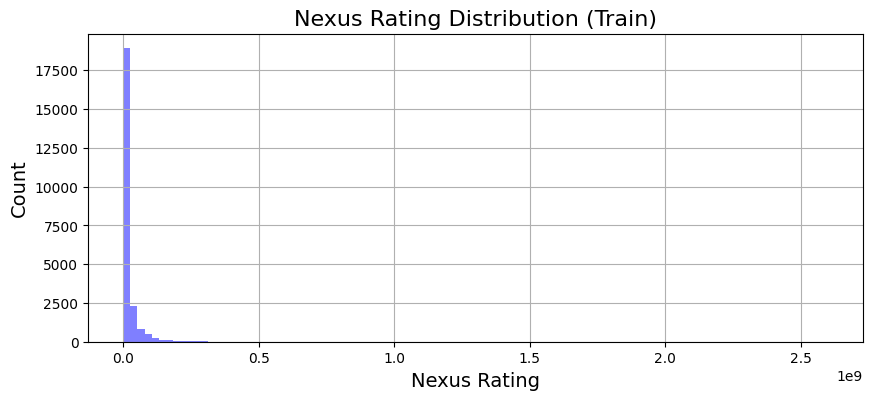

In [21]:
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
train['nexus_rating'].hist(bins=100, ax=ax, color='blue', alpha=0.5, label='Train Target Distributuon')
ax.set_title('Nexus Rating Distribution (Train)', fontsize=16)
ax.set_xlabel('Nexus Rating', fontsize=14)
ax.set_ylabel('Count', fontsize=14)

#### Rectifying test data

In [22]:
train.describe()

,ownership_type,nexus_rating,energy_footprint,core_reactor_size,harvesting_space,vertical_alignment,power_chambers,energy_flow_design,upper_collector_height,shared_conversion_units,isolated_conversion_units,internal_collectors,external_collectors,ambient_harvesters,shielded_harvesters,efficiency_grade,grid_connections
count,14455.000000,2.328500e+04,23285.000000,18564.000000,19403.000000,23285.000000,23285.000000,5643.000000,12192.000000,19413.000000,19413.000000,15213.000000,15213.000000,12765.000000,12765.000000,13475.000000,23205.000000
mean,1.875683,2.355617e+07,74.450999,12.552279,38.741367,8.969594,2.189349,1.039695,3.268374,0.737547,0.662855,0.797147,0.468678,0.556365,0.673090,1.270501,1.162293
std,1.089518,5.264393e+07,58.671373,6.565686,31.398480,8.322039,1.076130,0.351507,10.802728,0.781173,0.716888,0.402137,0.499034,0.641257,0.664779,1.017037,0.456937
min,0.000000,9.000000e+05,9.300000,1.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,7.490000e+06,42.000000,8.200000,20.000000,3.000000,1.000000,1.000000,2.650000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2.000000,1.064500e+07,59.800000,10.700000,30.900000,7.000000,2.000000,1.000000,2.800000,1.000000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000
75%,3.000000,2.050000e+07,84.800000,15.300000,45.300000,12.000000,3.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000
max,3.000000,2.600000e+09,2181.000000,100.000000,900.000000,95.000000,6.000000,2.000000,340.000000,4.000000,4.000000,1.000000,1.000000,4.000000,4.000000,3.000000,2.000000


In [23]:
test.describe()
# looks like columns after ownership type were shifted to the left

,ownership_type,nexus_rating,energy_footprint,core_reactor_size,harvesting_space,vertical_alignment,power_chambers,energy_flow_design,upper_collector_height,shared_conversion_units,isolated_conversion_units,internal_collectors,external_collectors,ambient_harvesters,shielded_harvesters,efficiency_grade,grid_connections
count,5995.000000,9937.000000,7704.000000,7918.000000,9937.000000,9937.000000,2569.000000,4919.000000,8220.000000,8220.000000,6449.000000,6449.000000,5102.000000,5102.000000,5978.000000,9897.000000,9.937000e+03
mean,1.805838,75.144219,12.874883,39.500515,9.184160,2.202878,1.036201,3.725885,0.776642,0.611922,0.809273,0.438518,0.584673,0.632301,1.259284,1.175003,2.327010e+07
std,1.087742,56.359318,6.878015,33.145228,7.963073,1.107315,0.334674,15.915162,0.811608,0.709386,0.392905,0.496244,0.645422,0.669174,1.041879,0.462727,4.345831e+07
min,0.000000,13.000000,1.200000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.400000e+06
25%,1.000000,42.400000,8.200000,20.000000,3.000000,1.000000,1.000000,2.650000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,7.599000e+06
50%,2.000000,59.600000,10.800000,31.000000,7.000000,2.000000,1.000000,2.800000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.100000e+07
75%,3.000000,86.000000,16.000000,45.400000,13.000000,3.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,2.074351e+07
max,3.000000,1175.000000,63.600000,528.000000,69.000000,6.000000,2.000000,350.000000,4.000000,4.000000,1.000000,1.000000,4.000000,4.000000,3.000000,2.000000,9.285855e+08


In [24]:
def rectify_data(test):
    new_test = pd.DataFrame()
    new_test['ownership_type'] = test['ownership_type']
    new_test['nexus_rating'] = test['grid_connections']
    for i in range(2,len(test.columns)):
        new_test[test.columns[i]] = test[test.columns[i-1]]
    return new_test

In [25]:
rectify_data(test).describe()
# Looks better now. The train and test sets should always come from the same distribution.

,ownership_type,nexus_rating,energy_footprint,core_reactor_size,harvesting_space,vertical_alignment,power_chambers,energy_flow_design,upper_collector_height,shared_conversion_units,isolated_conversion_units,internal_collectors,external_collectors,ambient_harvesters,shielded_harvesters,efficiency_grade,grid_connections
count,5995.000000,9.937000e+03,9937.000000,7704.000000,7918.000000,9937.000000,9937.000000,2569.000000,4919.000000,8220.000000,8220.000000,6449.000000,6449.000000,5102.000000,5102.000000,5978.000000,9897.000000
mean,1.805838,2.327010e+07,75.144219,12.874883,39.500515,9.184160,2.202878,1.036201,3.725885,0.776642,0.611922,0.809273,0.438518,0.584673,0.632301,1.259284,1.175003
std,1.087742,4.345831e+07,56.359318,6.878015,33.145228,7.963073,1.107315,0.334674,15.915162,0.811608,0.709386,0.392905,0.496244,0.645422,0.669174,1.041879,0.462727
min,0.000000,2.400000e+06,13.000000,1.200000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,7.599000e+06,42.400000,8.200000,20.000000,3.000000,1.000000,1.000000,2.650000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,2.000000,1.100000e+07,59.600000,10.800000,31.000000,7.000000,2.000000,1.000000,2.800000,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000
75%,3.000000,2.074351e+07,86.000000,16.000000,45.400000,13.000000,3.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000
max,3.000000,9.285855e+08,1175.000000,63.600000,528.000000,69.000000,6.000000,2.000000,350.000000,4.000000,4.000000,1.000000,1.000000,4.000000,4.000000,3.000000,2.000000


#### Data preparation

In [26]:
columns_with_na = train.columns[train.isna().any()].tolist()
# these are the columns we have to fix
for d in columns_with_na:
    print(d)

ownership_type
core_reactor_size
harvesting_space
energy_flow_design
upper_collector_height
shared_conversion_units
isolated_conversion_units
internal_collectors
external_collectors
ambient_harvesters
shielded_harvesters
efficiency_grade
grid_connections


In [254]:
# data preparation
def preprocess(data_in: pd.DataFrame):
    df = data_in.copy()
    # These two columns contain some 0 values. Here, however, it doesn't
    # make sense for these values to be 0, so we have to replace them somehow
    df['harvesting_space'] = np.where(df['harvesting_space'] > 0, df['harvesting_space'], np.nan)
    df['upper_collector_height'] = np.where(df['upper_collector_height'] > 0, df['upper_collector_height'], np.nan)

    return df

I use the same preprocess function on both the training and test set. However, because the sets have slightly different statistical medians, filling NA values with the set's medians is not technically correct, as we are applying a different transformation to each set. The difference is very small here, so this doesn't cause much problem, but the correct way is to fill NA values in the test set with the medians/modes from the training set. 

#### EDA / Feature engineering

In [255]:
def feature_engineering(df: pd.DataFrame):
    # NUMERIC DATA
    # Taking the logarithm seems appropriate here given the magnitude and distribution of these features
    df['core_reactor_size'] = np.log(df['core_reactor_size']) 
    df['nexus_rating'] = np.log(df['nexus_rating'])
    df['energy_footprint'] = np.log(df['energy_footprint'])
    df['vertical_alignment'] = np.log(df['vertical_alignment'])
    df['harvesting_space'] = np.log(df['harvesting_space'])
    df['upper_collector_height'] = np.log(df['upper_collector_height'])
    
    return df

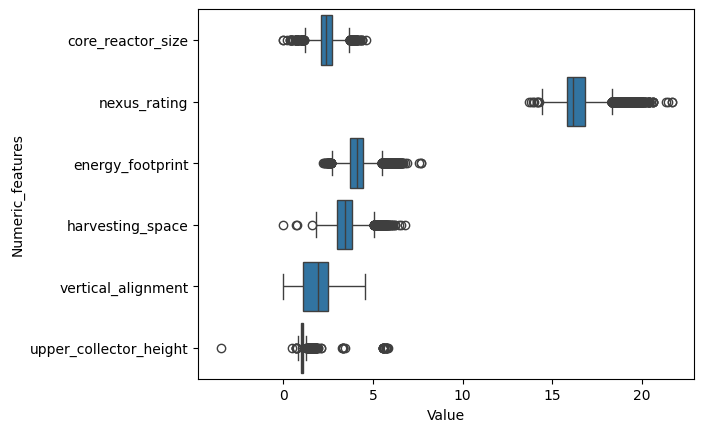

In [256]:
# Visualizing data
df = feature_engineering(preprocess(train))
df = df[['core_reactor_size','nexus_rating','energy_footprint','harvesting_space','vertical_alignment','upper_collector_height']]
df = df.melt(var_name='Numeric_features',value_name='Value')
sns.boxplot(x='Value',y='Numeric_features',data=df, orient='h')
plt.show()

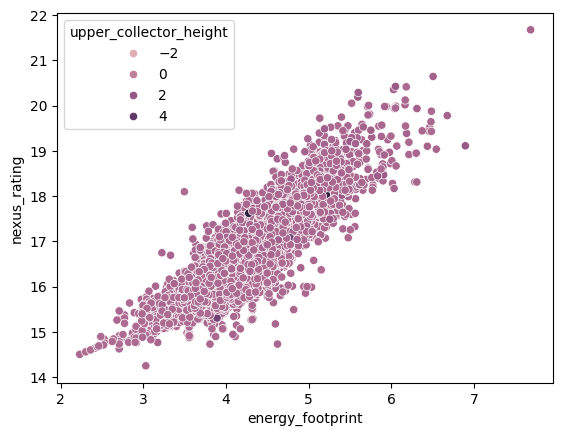

In [249]:
# we see a very good relationship between energy footprint and nexus rating, and lesser ones to for example upper core reactor size
df = preprocess(train)
df = feature_engineering(df)
ax = sns.scatterplot(x='energy_footprint',y='nexus_rating',hue='upper_collector_height',data=df)
plt.show()

#### Training

In [ ]:
import xgboost as xgb
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.ensemble import RandomForestRegressor

x_train = feature_engineering(preprocess(train))
y_train = x_train['nexus_rating']
x_train = x_train.drop('nexus_rating',axis=1)
x_test = feature_engineering(preprocess(rectify_data(test)))
x_test = x_test.drop('nexus_rating',axis=1)
y_test = preprocess(rectify_data(test))['nexus_rating']

# clf = xgb.XGBRegressor()
# clf = RandomForestRegressor()
clf = CatBoostRegressor()
# clf = LGBMRegressor()
clf.fit(x_train,y_train)
y_pred = np.exp(clf.predict(x_test))

Learning rate set to 0.067325
0:	learn: 0.8212892	total: 2.78ms	remaining: 2.77s
1:	learn: 0.7807983	total: 5.06ms	remaining: 2.52s
2:	learn: 0.7443084	total: 7.79ms	remaining: 2.59s
3:	learn: 0.7111505	total: 10.4ms	remaining: 2.58s
4:	learn: 0.6803031	total: 12.8ms	remaining: 2.54s
5:	learn: 0.6514044	total: 15.3ms	remaining: 2.53s
6:	learn: 0.6250932	total: 17.5ms	remaining: 2.49s
7:	learn: 0.5998796	total: 20.1ms	remaining: 2.5s
8:	learn: 0.5780259	total: 22.5ms	remaining: 2.48s
9:	learn: 0.5575590	total: 25.1ms	remaining: 2.48s
10:	learn: 0.5391435	total: 27.7ms	remaining: 2.49s
11:	learn: 0.5215277	total: 30ms	remaining: 2.47s
12:	learn: 0.5057920	total: 32.9ms	remaining: 2.5s
13:	learn: 0.4908576	total: 35.5ms	remaining: 2.5s
14:	learn: 0.4774953	total: 37.7ms	remaining: 2.48s
15:	learn: 0.4657146	total: 40.6ms	remaining: 2.5s
16:	learn: 0.4544115	total: 42.9ms	remaining: 2.48s
17:	learn: 0.4443504	total: 45.1ms	remaining: 2.46s
18:	learn: 0.4349052	total: 47.6ms	remaining: 2.46

#### Evaluation

In [265]:
from sklearn.metrics import mean_squared_log_error

def rmsle(y_true, y_pred):
    """ Root Mean Squared Logarithmic Error """
    return np.sqrt(mean_squared_log_error(y_true, y_pred))

In [266]:
print('RMSLE: ', f'{rmsle(y_test,y_pred):.3f}')
print('Required RMSLE: ', 0.294)

RMSLE:  0.298
Required RMSLE:  0.294


##### Discussion

a) I don't understand this question. Probabilty thresholds apply to classifiers but this problem is about regression.

b) RMSLE is a suitable metric when when we are more interested in relative error, i.e. not in the absolute size of the error but in the error relative to the magnitude of the values in the data and target. Here, because the energy consumption spans a wide range of magnitudes, this metric is preferable. When training the model I used the squared error loss because the (engineered) data seemed to imply a linear relationship between the features.

c) See graph below. We see that energy footprint is the most important feature for prediction, which is unsurprising given what we found during EDA. The rest of the data was really faulty and a large portion of it comes from our choice of data filling, so it is also unsurprising that it has lower correlation with the target. We could potentially use other techinques like iterative imputation to try to get more representative data.

d) Here I tried using some different regressors, and they give about the same results (and same feature importance). LGBM and CatBoost Give marginally better results than RFR and XGB.

e) We can create a test set from splitting it from our total data set, or use techniques like cross validation on the entire set. Regardless, the most important is making sure that our model is trained on data that comes from the same distribution as the unseen data. If we haven't overfitted, then a model that performs well on the data we have should perform well on the unseen data. 

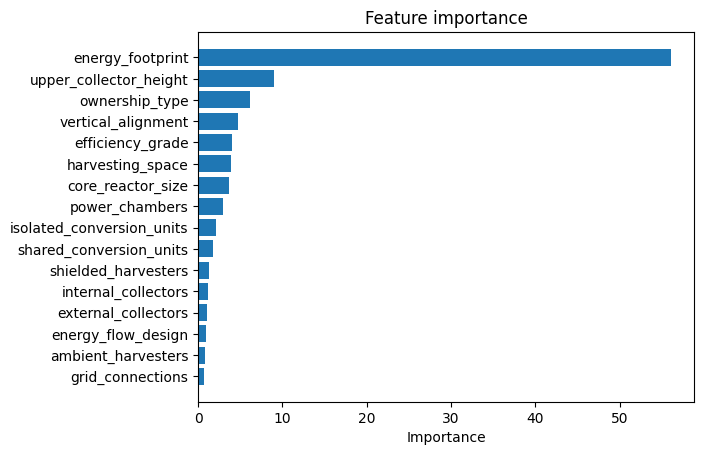

In [232]:
# Feature importance from XGB
importances = zip(x_train.columns,clf.feature_importances_)
importances = sorted(importances,key=lambda x: x[1])
plt.barh(y=[k for k,v in importances],width=[v for k,v in importances])#
plt.title('Feature importance')
plt.xlabel('Importance')
plt.show()